# NYC Taxi — Öğrenci 4 ders gösterimi: yolculuk süresi tahmini

**Soru:** Bir taksi yolculuğunun kaç dakika süreceğini biniş anındaki bilgilerden tahmin edebilir miyiz? Aynı modeli **PySpark MLlib** ve klasik Python (**scikit-learn**) ile eğittiğimizde doğruluk, süre ve bellek nasıl değişir?

**Ne yaptım?**
1. 17.210.961 temiz yolculuktan iç içe üç örneklem aldım: **100K ⊂ 1M ⊂ 5M**.
2. İki model ailesini (doğrusal regresyon ve gradyan artırmalı ağaç) iki çerçevede **aynı satırlar, aynı özellikler ve aynı ayarlarla** eğittim. Toplam 12 deney yaptım.
3. Her deneyi ayrı bir süreçte çalıştırıp doğruluğu (RMSE, MAE, R²), eğitim süresini ve **tepe belleği** ölçtüm. Spark tarafında JVM de ölçüme dahildi.
4. İlk sürümdeki üç ölçüm hatasını düzelttim ve bütün sonuçları yeniden ürettim.

**İçerik** · [1. Görev](#1.-Görev-ve-veri) · [2. Adil karşılaştırma](#2.-Adil-karşılaştırma) · [3. Doğruluk](#3.-Bulgu-1-—-Doğruluk) · [4. Süre](#4.-Bulgu-2-—-Eğitim-süresi) · [5. Bellek](#5.-Bulgu-3-—-Bellek) · [6. Model neye bakıyor?](#6.-Model-neye-bakıyor?) · [7. İlk sürümden ne değişti?](#7.-İlk-sürümden-ne-değişti?) · [8. Sonuç](#8.-Sonuç)

> Bu notebook yalnızca `reports/results/` altındaki kayıtlı sonuçları okur. Veri veya Spark kurulumu gerekmez, birkaç saniyede baştan çalışır. Deneyleri yeniden üretmek için: `python -m src.ml_duration`.

In [1]:
import inspect
import io
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import IFrame, Image, Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
INK = "#52514e"


def tr_dec(x, n=2):
    return f"{x:,.{n}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def tr_int(x):
    return f"{int(round(x)):,}".replace(",", ".")


def md(text):
    display(Markdown(text))


def show(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    display(Image(buffer.getvalue()))


def show_code(*functions):
    for fn in functions:
        md(f"`{fn.__module__}.{fn.__name__}`\n```python\n{inspect.getsource(fn).rstrip()}\n```")

from src import ml_duration as s4

SPARK, SKLEARN = "#2a78d6", "#eb6834"
COLOR = {"PySpark": SPARK, "scikit-learn": SKLEARN}
FAMILY = {"LinearRegression": "Doğrusal", "GBTRegressor": "Ağaç (GBT)",
          "HistGradientBoosting": "Ağaç (GBT)"}
STYLE = {"Doğrusal": "--", "Ağaç (GBT)": "-"}
SIZES = s4.SAMPLE_LABELS

comp = pd.read_csv(s4.COMPARISON_CSV)
comp["family"] = comp["model"].map(FAMILY)
comp["label"] = comp["framework"] + " · " + comp["model"]
importance = pd.read_csv(s4.IMPORTANCE_CSV)
pred = pd.read_csv(s4.PRED_SAMPLE_CSV)

assert len(comp) == 12 and comp["error"].isna().all()
assert set(comp["size_label"]) == set(SIZES)
md(f"**{len(comp)} deney** yüklendi: 2 çerçeve × 2 model × {len(SIZES)} boyut. Hata veren deney yok.")

**12 deney** yüklendi: 2 çerçeve × 2 model × 3 boyut. Hata veren deney yok.

## 1. Görev ve veri

**Hedef:** `trip_duration_min` (iniş − biniş, 1–180 dk). **Kaynak:** Öğrenci 2'nin temiz verisi.

Örneklemler Öğrenci 1'in `xxhash64` anahtarıyla seçildi. Bu yüzden makineden bağımsızlar ve iç içeler: 100K'daki her satır 1M'de de var. Eğitim/test ayrımı (%80/%20) da satır hash'iyle yapıldı. **İki çerçeve birebir aynı satırları görüyor.**

In [2]:
sizes = (comp.drop_duplicates("size_label").set_index("size_label").loc[SIZES]
         [["size_n", "n_train", "n_test"]])
display(sizes.rename(columns={"size_n": "Kayıt", "n_train": "Eğitim", "n_test": "Test"})
        .rename_axis("Örneklem").map(tr_int))

ACIKLAMA = {
    "trip_distance": "Mesafe (mil)", "pickup_hour": "Biniş saati", "pickup_dow": "Haftanın günü",
    "extra": "Ek ücret (gece / yoğun saat)", "mta_tax": "MTA vergisi",
    "tolls_amount": "Köprü / tünel ücreti", "improvement_surcharge": "İyileştirme ek ücreti",
    "cbd_congestion_fee": "Manhattan trafik ücreti",
    "PULocationID": "Biniş bölgesi (kategorik)", "DOLocationID": "İniş bölgesi (kategorik)",
}
features = s4.NUMERIC_FEATURES + s4.LOCATION_COLS
assert set(features) == set(ACIKLAMA)
display(pd.DataFrame({"Özellik": features, "Anlamı": [ACIKLAMA[f] for f in features]})
        .set_index("Özellik"))

,Kayıt,Eğitim,Test
Örneklem,,,
100K,99.327,79.549,19.778
1M,996.899,798.285,198.614
5M,4.996.842,3.997.515,999.327


,Anlamı
Özellik,
trip_distance,Mesafe (mil)
pickup_hour,Biniş saati
pickup_dow,Haftanın günü
extra,Ek ücret (gece / yoğun saat)
mta_tax,MTA vergisi
tolls_amount,Köprü / tünel ücreti
improvement_surcharge,İyileştirme ek ücreti
cbd_congestion_fee,Manhattan trafik ücreti
PULocationID,Biniş bölgesi (kategorik)


**Dışarıda bırakılanlar:** `fare_amount`, `total_amount`, `tip_amount` ve iniş zamanı süreyi doğrudan ele verir (**leakage**). `passenger_count`, `RatecodeID` gibi kolonlar Flex Fare kayıtlarında (%25,5) kasıtlı olarak boş. `dropna()` bu kayıtları sessizce silerdi, bu yüzden kullanılmadı.

## 2. Adil karşılaştırma

İki çerçeveyi kıyaslamak için dört şeyi sabit tuttum:

| Sabit tutulan | Nasıl |
|---|---|
| **Aynı satırlar** | Örneklem ve train/test ayrımı diske bir kez yazıldı, iki çerçeve aynı dosyayı okur. |
| **Aynı özellikler** | 8 sayısal kolon ve 2 bölge kolonu. En sık 254 bölge kendi kodunu alır, kalanlar "diğer" koduna düşer (255 kod). |
| **Aynı ayarlar** | Aşağıdaki tablo modül sabitlerinden ve gerçek scikit-learn nesnesinden üretildi. |
| **Ayrı süreç** | Her deney ayrı bir alt süreçte çalışır. Bellek 50 ms'de bir örneklenir ve süreç ağacının tamamı ölçülür (Python + JVM). |

In [3]:
hgb = s4.build_sklearn_model("gbt").get_params()
assert (hgb["max_iter"], hgb["max_depth"], hgb["learning_rate"], hgb["min_samples_leaf"]) == (
    s4.GBT_MAX_ITER, s4.GBT_MAX_DEPTH, s4.GBT_LEARNING_RATE, s4.GBT_MIN_LEAF)

display(pd.DataFrame([
    ("Ağaç sayısı", f"maxIter = {s4.GBT_MAX_ITER}", f"max_iter = {hgb['max_iter']}"),
    ("Derinlik", f"maxDepth = {s4.GBT_MAX_DEPTH}", f"max_depth = {hgb['max_depth']}"),
    ("Öğrenme oranı", f"stepSize = {s4.GBT_LEARNING_RATE}", f"learning_rate = {hgb['learning_rate']}"),
    ("Yaprakta en az kayıt", f"minInstancesPerNode = {s4.GBT_MIN_LEAF}", f"min_samples_leaf = {hgb['min_samples_leaf']}"),
    ("Bölge özelliği", f"kategorik (maxBins = {s4.GBT_MAX_BINS})", "kategorik (categorical_features)"),
    ("Erken durdurma", "yok", f"early_stopping = {hgb['early_stopping']}"),
], columns=["Ayar", "PySpark GBTRegressor", "scikit-learn HistGradientBoosting"]).set_index("Ayar"))

,PySpark GBTRegressor,scikit-learn HistGradientBoosting
Ayar,,
Ağaç sayısı,maxIter = 50,max_iter = 50
Derinlik,maxDepth = 5,max_depth = 5
Öğrenme oranı,stepSize = 0.1,learning_rate = 0.1
Yaprakta en az kayıt,minInstancesPerNode = 20,min_samples_leaf = 20
Bölge özelliği,kategorik (maxBins = 256),kategorik (categorical_features)
Erken durdurma,yok,early_stopping = False


**Sağlama.** Düzenlileştirmesiz doğrusal regresyonun (OLS) tek bir doğru cevabı vardır. Veri ve özellikler gerçekten aynıysa iki çerçeve aynı hatayı vermelidir:

In [4]:
lr = comp[comp["family"] == "Doğrusal"].pivot(index="size_label", columns="framework", values="rmse").loc[SIZES]
lr["Fark (dk)"] = (lr["PySpark"] - lr["scikit-learn"]).abs()
max_diff = lr["Fark (dk)"].max()
assert max_diff < 0.002
display(lr.rename_axis("Örneklem").rename_axis(None, axis=1).map(lambda v: tr_dec(v, 4)))
md(f"En büyük fark **{tr_dec(max_diff, 4)} dk**, yani 0,1 saniyeden az. Kalan doğruluk farkları veriden değil, algoritmaların uygulanışından geliyor.")

,PySpark,scikit-learn,Fark (dk)
Örneklem,,,
100K,"7,2018","7,2007","0,0011"
1M,"7,1697","7,1700","0,0003"
5M,"7,1754","7,1760","0,0006"


En büyük fark **0,0011 dk**, yani 0,1 saniyeden az. Kalan doğruluk farkları veriden değil, algoritmaların uygulanışından geliyor.

## 3. Bulgu 1 — Doğruluk

**Ağaç modeli 5M'de RMSE'yi 7,18 dakikadan 5,48 dakikaya indiriyor (%24 daha iyi, R² 0,65 → 0,79). Veri büyüdükçe yalnızca ağaç modeli iyileşiyor.**

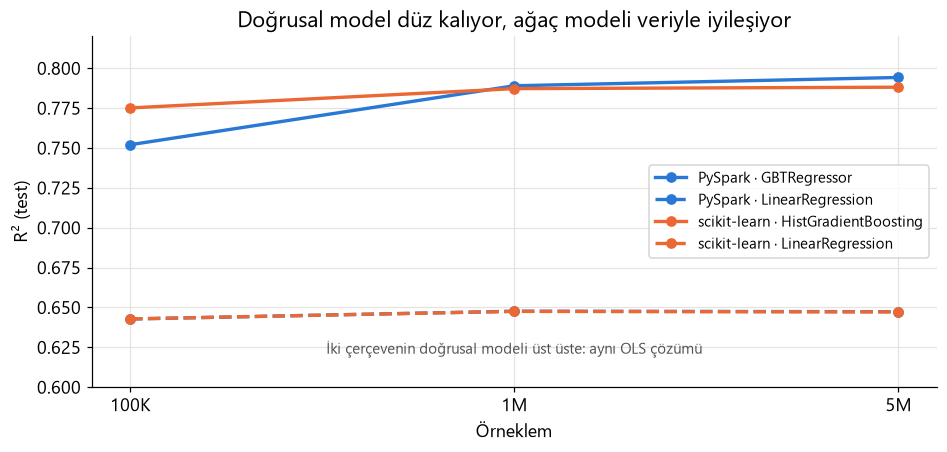

,100K,1M,5M
R²,,,
PySpark · GBTRegressor,"0,752","0,789","0,794"
PySpark · LinearRegression,"0,643","0,648","0,647"
scikit-learn · HistGradientBoosting,"0,775","0,787","0,788"
scikit-learn · LinearRegression,"0,643","0,647","0,647"


In [5]:
big = comp[comp["size_label"] == "5M"].set_index("label")
lr5 = big.loc["PySpark · LinearRegression"]
gbt5 = big.loc["PySpark · GBTRegressor"]
gain = 1 - gbt5.rmse / lr5.rmse
md(f"**Ağaç modeli 5M'de RMSE'yi {tr_dec(lr5.rmse)} dakikadan {tr_dec(gbt5.rmse)} dakikaya indiriyor "
   f"(%{tr_dec(100 * gain, 0)} daha iyi, R² {tr_dec(lr5.r2)} → {tr_dec(gbt5.r2)}). "
   "Veri büyüdükçe yalnızca ağaç modeli iyileşiyor.**")

fig, ax = plt.subplots(figsize=(8.5, 4), layout="constrained")
for (framework, model), grp in comp.groupby(["framework", "model"]):
    grp = grp.set_index("size_label").loc[SIZES]
    ax.plot(SIZES, grp["r2"], color=COLOR[framework], linestyle=STYLE[FAMILY[model]],
            marker="o", linewidth=2.2, label=f"{framework} · {model}")
ax.set(ylabel="R² (test)", xlabel="Örneklem", ylim=(0.6, 0.82),
       title="Doğrusal model düz kalıyor, ağaç modeli veriyle iyileşiyor")
ax.annotate("İki çerçevenin doğrusal modeli üst üste: aynı OLS çözümü",
            (1, comp[comp["family"] == "Doğrusal"]["r2"].mean()), xytext=(0, -26),
            textcoords="offset points", ha="center", fontsize=10, color=INK)
ax.legend(loc="center right", fontsize=10)
show(fig)

table = comp.pivot(index="label", columns="size_label", values="r2")[SIZES]
display(table.rename_axis("R²").rename_axis(None, axis=1).map(lambda v: tr_dec(v, 3)))

**Neden?**
- **Doğrusal model düz kalıyor (R² ≈ 0,65).** Süre mesafeyle doğrusal artmaz. Manhattan içinde yoğun saatte 2 mil, havalimanı otoyolunda 2 milden çok daha uzun sürer. Doğrusal model bu **etkileşimleri** temsil edemez. Hatası yanlılıktan (bias) gelir ve daha fazla veri bunu düzeltmez.
- **Ağaç modeli büyüyor.** Mesafe × bölge × saat etkileşimlerini bölmelerle yakalar. Nadir bölgeler ancak büyük örneklemde "yaprakta en az 20 kayıt" koşulunu sağlayıp kendi bölmesini alabilir.
- **İki çerçevenin GBT'si birebir aynı değil.** Başlangıç değeri ve bin sınırları farklı hesaplanıyor. 5M'de aradaki fark yalnızca 0,08 dakika.

## 4. Bulgu 2 — Eğitim süresi

**Ağaç modelinde scikit-learn, Spark'tan 100K'da 111×, 5M'de 41× daha hızlı. Doğrusal modelde ise sıra 1M'de tersine dönüyor: 5M'de Spark 2,6× önde.**

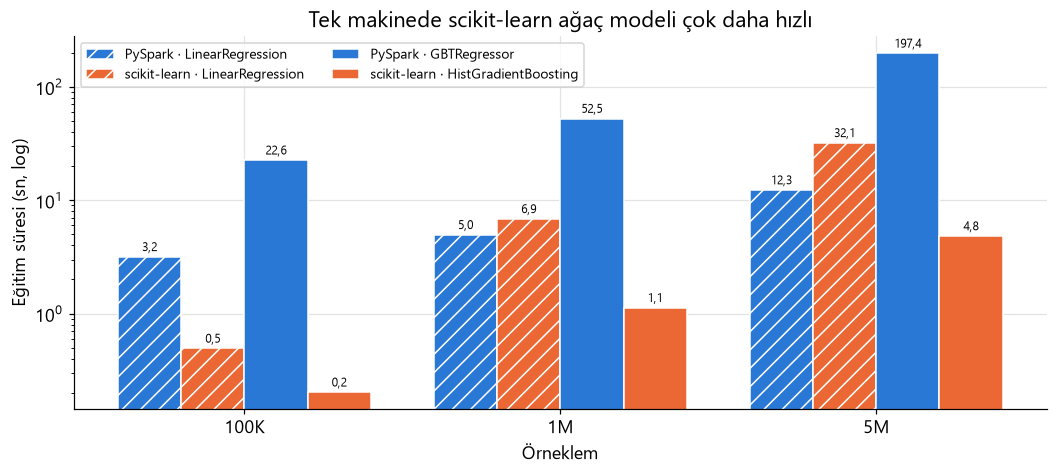

,GBT: Spark / sklearn,Doğrusal: sklearn / Spark
Örneklem,,
100K,"111,1×","0,2×"
1M,"46,5×","1,4×"
5M,"40,8×","2,6×"


In [6]:
times = comp.pivot(index="size_label", columns="label", values="train_time_s").loc[SIZES]
gbt_ratio = times["PySpark · GBTRegressor"] / times["scikit-learn · HistGradientBoosting"]
lr_ratio = times["scikit-learn · LinearRegression"] / times["PySpark · LinearRegression"]
md(f"**Ağaç modelinde scikit-learn, Spark'tan 100K'da {tr_dec(gbt_ratio['100K'], 0)}×, "
   f"5M'de {tr_dec(gbt_ratio['5M'], 0)}× daha hızlı. Doğrusal modelde ise sıra 1M'de tersine dönüyor: "
   f"5M'de Spark {tr_dec(lr_ratio['5M'], 1)}× önde.**")

order = ["PySpark · LinearRegression", "scikit-learn · LinearRegression",
         "PySpark · GBTRegressor", "scikit-learn · HistGradientBoosting"]
fig, ax = plt.subplots(figsize=(9.5, 4.2), layout="constrained")
x = np.arange(len(SIZES))
width = 0.2
for i, label in enumerate(order):
    framework = label.split(" · ")[0]
    hatch = "//" if "Linear" in label else None
    bars = ax.bar(x + (i - 1.5) * width, times[label], width, color=COLOR[framework],
                  hatch=hatch, edgecolor="white", label=label)
    ax.bar_label(bars, labels=[tr_dec(v, 1) for v in times[label]], fontsize=8, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, SIZES)
ax.set(ylabel="Eğitim süresi (sn, log)", xlabel="Örneklem",
       title="Tek makinede scikit-learn ağaç modeli çok daha hızlı")
ax.legend(fontsize=9, ncol=2, loc="upper left")
show(fig)

display(pd.DataFrame({"GBT: Spark / sklearn": gbt_ratio, "Doğrusal: sklearn / Spark": lr_ratio})
        .rename_axis("Örneklem").map(lambda v: tr_dec(v, 1) + "×"))

**Neden Spark ağaçta yavaş?**
- Spark her ağaç seviyesini ayrı bir iş (job) olarak zamanlar. 50 ağaç × 5 seviye, yüzlerce iş demek.
- Veri JVM ile Python arasında serileştirilir ve her görevin sabit bir başlatma maliyeti vardır.
- Histogramlar görevlerden toplanıp shuffle ile birleştirilir.
- scikit-learn ise önceden binlenmiş `uint8` matris üzerinde çok iş parçacıklı C++/Cython kodu çalıştırır.

Veri büyüdükçe Spark'ın sabit maliyeti toplam içinde küçülür, bu yüzden oran 100K'dan 5M'e düşüyor.

**Doğrusal modelde neden tersi?** Spark normal denklemleri (XᵀX, 516 × 516) tek geçişte ve paralel kurar. scikit-learn seyrek one-hot matriste tek çekirdekli iteratif `lsqr` çözücüsü kullanır. Yani **algoritma ve paralellik seçimi, motor seçiminden daha belirleyici.**

## 5. Bulgu 3 — Bellek

**Spark'ın sabit bir taban maliyeti var: veri yüklü ve eğitim başlamadan önce bile ~0,5 GB. 5M'de Spark GBT 4,2 GB'a çıkıyor, scikit-learn HGB 2,2 GB'ta kalıyor.**

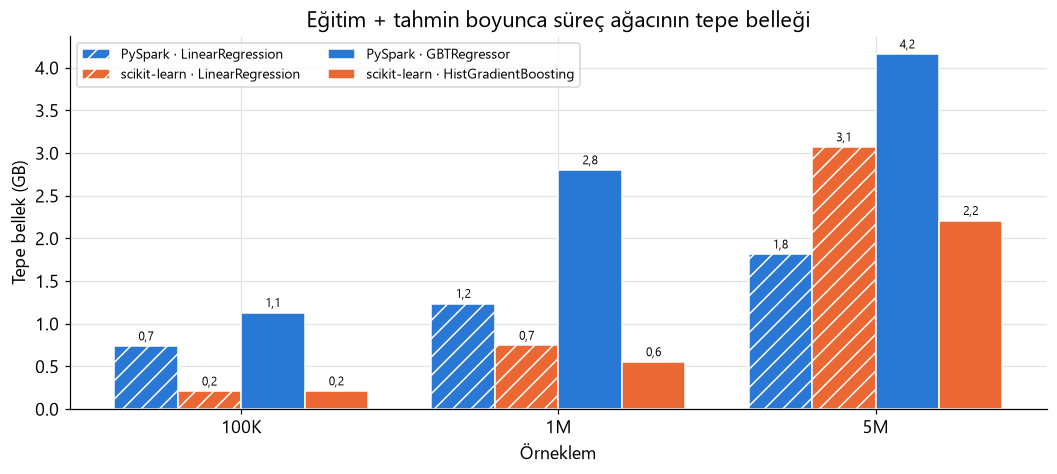

,KB / kayıt,32 GB'ın dolduğu yer (doğrusal tahmin)
Model,,
scikit-learn · LinearRegression,"0,60",~56M kayıt
scikit-learn · HistGradientBoosting,"0,42",~80M kayıt


In [7]:
mem = comp.pivot(index="size_label", columns="label", values="peak_rss_mb").loc[SIZES] / 1000
jvm_base = comp.loc[comp["framework"] == "PySpark", "rss_before_fit_mb"].min()
md(f"**Spark'ın sabit bir taban maliyeti var: veri yüklü ve eğitim başlamadan önce bile ~{tr_dec(jvm_base / 1000, 1)} GB. "
   f"5M'de Spark GBT {tr_dec(mem.loc['5M', 'PySpark · GBTRegressor'], 1)} GB'a çıkıyor, "
   f"scikit-learn HGB {tr_dec(mem.loc['5M', 'scikit-learn · HistGradientBoosting'], 1)} GB'ta kalıyor.**")

fig, ax = plt.subplots(figsize=(9.5, 4.2), layout="constrained")
for i, label in enumerate(order):
    framework = label.split(" · ")[0]
    hatch = "//" if "Linear" in label else None
    bars = ax.bar(x + (i - 1.5) * width, mem[label], width, color=COLOR[framework],
                  hatch=hatch, edgecolor="white", label=label)
    ax.bar_label(bars, labels=[tr_dec(v, 1) for v in mem[label]], fontsize=8, padding=2)
ax.set_xticks(x, SIZES)
ax.set(ylabel="Tepe bellek (GB)", xlabel="Örneklem",
       title="Eğitim + tahmin boyunca süreç ağacının tepe belleği")
ax.legend(fontsize=9, ncol=2, loc="upper left")
show(fig)

RAM_MB = 32 * 1024
rows = []
for label in ("scikit-learn · LinearRegression", "scikit-learn · HistGradientBoosting"):
    grp = comp[comp["label"] == label]
    slope, intercept = np.polyfit(grp["size_n"], grp["peak_rss_mb"], 1)
    rows.append({"Model": label, "KB / kayıt": tr_dec(slope * 1024, 2),
                 "32 GB'ın dolduğu yer (doğrusal tahmin)": f"~{tr_dec((RAM_MB - intercept) / slope / 1e6, 0)}M kayıt"})
display(pd.DataFrame(rows).set_index("Model"))

**Neden?** Spark'ın JVM'i, önbellekteki veri ve ağaç başına histogram tamponları ek bellek tutar. scikit-learn'ün belleği ise kayıt sayısıyla doğrusal artar. Bu makinede (32 GB) doğrusal tahminle birkaç on milyon kayıtta RAM dolar. Spark o noktadan sonra da diske taşarak (spill) veya kümeye dağıtarak çalışabilir. Bu sınırı **ölçmedik**, yalnızca tahmin ediyoruz.

**Dikkat:** scikit-learn doğrusal model 5M'de Spark'tan fazla bellek kullanıyor. Sebebi seyrek one-hot matris ve çözücünün tuttuğu kopyalar. "Klasik yaklaşım hep az bellek kullanır" demek de doğru değil.

## 6. Model neye bakıyor?

Özellik önemi: Spark GBT, 1M örneklem. Bölge kolonları tek bir kategorik özellik olarak görünür.

**Mesafe tek başına 0,47. Bölgelerin toplamı (0,31), saat ve günün toplamından (0,21) büyük: nereden nereye gidildiği, ne zaman gidildiğinden daha belirleyici.**

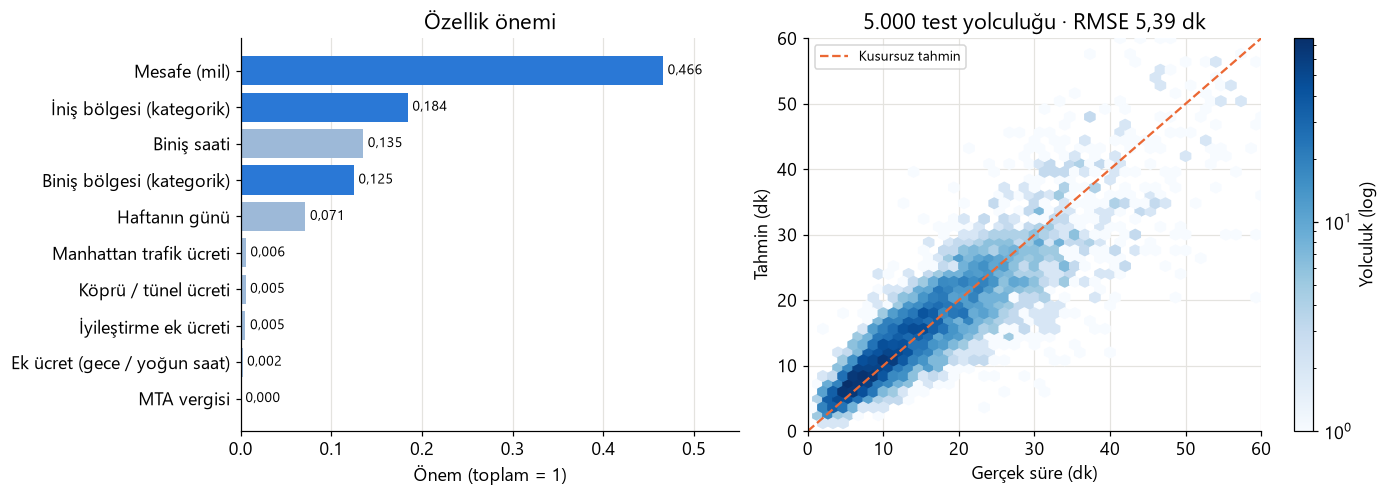

In [8]:
imp = importance.set_index("feature")["importance"].sort_values()
zone_total = imp[s4.LOCATION_COLS].sum()
time_total = imp[["pickup_hour", "pickup_dow"]].sum()
md(f"**Mesafe tek başına {tr_dec(imp['trip_distance'], 2)}. Bölgelerin toplamı ({tr_dec(zone_total, 2)}), "
   f"saat ve günün toplamından ({tr_dec(time_total, 2)}) büyük: nereden nereye gidildiği, ne zaman gidildiğinden daha belirleyici.**")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), layout="constrained",
                               gridspec_kw={"width_ratios": [1.1, 1]})
colors = [SPARK if f in s4.LOCATION_COLS or f == "trip_distance" else "#9db9d8" for f in imp.index]
bars = ax1.barh([ACIKLAMA[f] for f in imp.index], imp.values, color=colors)
ax1.bar_label(bars, labels=[tr_dec(v, 3) for v in imp.values], padding=3, fontsize=9)
ax1.set(xlabel="Önem (toplam = 1)", title="Özellik önemi", xlim=(0, 0.55))
ax1.grid(axis="y", visible=False)

err = pred["prediction"] - pred["trip_duration_min"]
hb = ax2.hexbin(pred["trip_duration_min"], pred["prediction"], gridsize=45, bins="log",
                cmap="Blues", extent=(0, 60, 0, 60), mincnt=1)
ax2.plot([0, 60], [0, 60], color=SKLEARN, linewidth=1.5, linestyle="--", label="Kusursuz tahmin")
ax2.set(xlim=(0, 60), ylim=(0, 60), xlabel="Gerçek süre (dk)", ylabel="Tahmin (dk)",
        title=f"{tr_int(len(pred))} test yolculuğu · RMSE {tr_dec(np.sqrt((err ** 2).mean()))} dk")
ax2.legend(loc="upper left", fontsize=9)
fig.colorbar(hb, ax=ax2, label="Yolculuk (log)")
show(fig)

Noktalar köşegen çevresinde toplanıyor. Hata süreye göre nasıl değişiyor?

In [9]:
bands = pd.cut(pred["trip_duration_min"], [0, 10, 20, 40, 60, 181],
               labels=["0–10 dk", "10–20 dk", "20–40 dk", "40–60 dk", "60+ dk"], right=False)
bias = pred.assign(err=err, band=bands).groupby("band", observed=True).agg(
    n=("err", "size"), bias=("err", "mean"), mae=("err", lambda e: e.abs().mean()))
display(pd.DataFrame({"Yolculuk": bias["n"].map(tr_int),
                      "Ortalama sapma (dk)": bias["bias"].map(lambda v: ("+" if v > 0 else "−") + tr_dec(abs(v), 1)),
                      "Ortalama mutlak hata (dk)": bias["mae"].map(lambda v: tr_dec(v, 1))})
        .rename_axis("Gerçek süre"))
long_bias = bias.loc["60+ dk", "bias"]
md(f"**Model kısa yolculukları biraz uzun, uzun yolculukları belirgin biçimde kısa tahmin ediyor "
   f"(60+ dk'da ortalama {tr_dec(abs(long_bias), 0)} dk eksik).** Trafik sıkışıklığı ve kaza gibi biniş anında bilinmeyen etkenler "
   "uzun yolculukları daha da uzatıyor. Model bu kuyruğu göremiyor ve ortalamaya çekiyor.")
md("**Sınırlama:** `tolls_amount` ve `cbd_congestion_fee` yolculuk sonunda kesinleşir. Toplam önemleri çok küçük, "
   "ama gerçek zamanlı bir sistemde çıkarılmaları gerekir.")

,Yolculuk,Ortalama sapma (dk),Ortalama mutlak hata (dk)
Gerçek süre,,,
0–10 dk,1.629,"+1,5","2,1"
10–20 dk,1.955,"+0,7","2,9"
20–40 dk,1.186,"−1,9","5,1"
40–60 dk,169,"−5,7","9,9"
60+ dk,61,"−16,0","16,4"


**Model kısa yolculukları biraz uzun, uzun yolculukları belirgin biçimde kısa tahmin ediyor (60+ dk'da ortalama 16 dk eksik).** Trafik sıkışıklığı ve kaza gibi biniş anında bilinmeyen etkenler uzun yolculukları daha da uzatıyor. Model bu kuyruğu göremiyor ve ortalamaya çekiyor.

**Sınırlama:** `tolls_amount` ve `cbd_congestion_fee` yolculuk sonunda kesinleşir. Toplam önemleri çok küçük, ama gerçek zamanlı bir sistemde çıkarılmaları gerekir.

## 7. İlk sürümden ne değişti?

İlk sürümdeki karşılaştırmada üç ölçüm hatası vardı. Hepsini düzeltip bütün deneyleri yeniden çalıştırdım:

| # | Hata | Düzeltme |
|---|---|---|
| 1 | scikit-learn 17,2M satırın **tamamını** okuyup sonra örnekliyordu. Ölçülen bellek modelin değil, okumanın maliyetiydi. | Yalnızca örneklem okunuyor. |
| 2 | Spark belleği yalnızca Python sürecinden ölçülüyordu (~72 MB). İşi yapan **JVM ölçülmüyordu**, değer de tepe değil anlık değerdi. | Süreç ağacının tepe belleği 50 ms'de bir örnekleniyor. |
| 3 | scikit-learn'e **bölge bilgisi verilmemişti**, iterasyon sayıları farklıydı (100 ve 15). Özellik önemindeki `DOLocationID_40` bölge 40 değil, sıra numarasıydı. | Aynı özellikler, aynı ayarlar, gerçek kolon adları. |

In [10]:
# İlk sürümün değerleri: commit 2be08b5, reports/results/s4_spark_results.csv ve s4_sklearn_comparison.csv
ILK_SURUM = {
    "Spark GBT tepe bellek, 5M": ("72 MB", "PySpark · GBTRegressor", "peak_rss_mb", "5M"),
    "sklearn HGB tepe bellek, 100K": ("2.443 MB", "scikit-learn · HistGradientBoosting", "peak_rss_mb", "100K"),
    "Spark GBT R², 5M": ("0,730", "PySpark · GBTRegressor", "r2", "5M"),
    "sklearn HGB R², 5M": ("0,761", "scikit-learn · HistGradientBoosting", "r2", "5M"),
}
rows = []
for name, (old, label, col, size) in ILK_SURUM.items():
    value = comp[(comp["label"] == label) & (comp["size_label"] == size)][col].item()
    new = f"{tr_int(value)} MB" if col == "peak_rss_mb" else tr_dec(value, 3)
    rows.append({"Ölçüm": name, "İlk sürüm": old, "Düzeltilmiş": new})
display(pd.DataFrame(rows).set_index("Ölçüm"))

,İlk sürüm,Düzeltilmiş
Ölçüm,,
"Spark GBT tepe bellek, 5M",72 MB,4.161 MB
"sklearn HGB tepe bellek, 100K",2.443 MB,212 MB
"Spark GBT R², 5M","0,730","0,794"
"sklearn HGB R², 5M","0,761","0,788"


İlk sürümün ana sonucu **"Spark çok az bellek kullanıyor, scikit-learn çok fazla"** idi. Bu sonuç ölçüm hatasından kaynaklanıyordu ve düzeltmeden sonra tersine döndü. Bölge bilgisi eklenince iki çerçevenin doğruluğu da arttı.

## 8. Sonuç

**Araştırma sorusu:** Veri büyüdükçe klasik yaklaşım ne zaman yetersiz kalıyor?

- **5M kayda kadar, RAM'e sığan veride klasik yaklaşım yetersiz kalmıyor.** scikit-learn ağaç modelinde hem çok daha hızlı hem daha az bellek kullanıyor. Doğruluk farkı 0,1 dakikanın altında.
- **Spark'ın sabit maliyetleri var:** JVM belleği ve iş başına zamanlama. Bu maliyetler tek makinede küçük veride amorti olmuyor.
- **Algoritma seçimi motor seçiminden önemli.** Doğrusal modelde paralel normal denklemler sayesinde Spark 1M'den itibaren daha hızlı.
- **Klasik yaklaşımın sert sınırı bellek.** Doğrusal tahminle 32 GB, birkaç on milyon kayıtta dolar. Spark'ın gerçek getirisi veri RAM'i aştığında veya birden çok makineye dağıtmak gerektiğinde ortaya çıkar.

### Sorulursa

| Soru | Kısa cevap ve kanıt |
|---|---|
| Karşılaştırma adil mi? | Aynı satırlar, özellikler ve ayarlar kullanıldı. OLS iki çerçevede aynı hatayı veriyor (§2). |
| Neden `fare_amount` kullanılmadı? | Ücret süreye göre hesaplanır, yani cevabı içinde taşır (leakage). |
| Neden R² 0,8 civarında kalıyor? | Trafik ve hava durumu gibi biniş anında bilinmeyen etkenler var (§6, uzun yolculuklar). |
| Spark neden bu kadar yavaş? | Her ağaç seviyesi ayrı bir iş. Serileştirme ve shuffle maliyeti tek makinede amorti olmuyor (§4). |
| Sayılar neden ilk sürümden farklı? | Üç ölçüm hatası düzeltildi (§7). |
| Daha büyük veride ne olur? | scikit-learn belleği doğrusal artıyor, doğrusal tahminle birkaç on milyon kayıtta 32 GB dolar. Bunu ölçmedik (§5). |

Ayrıntılar: [Teknik rapor](../docs/technical_report_s4.md) · [Tam notebook](04_ml_duration_prediction.ipynb) · [Sınav soruları](../docs/exam_questions_s4.md)